In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os
DRIVE_PROJECT_DIR = '/content/drive/MyDrive/MovieMind'
ARTIFACT_DIR = os.path.join(DRIVE_PROJECT_DIR, 'model_artifacts')
os.makedirs(ARTIFACT_DIR, exist_ok=True)

print('Artifacts will be saved to:', ARTIFACT_DIR)

Mounted at /content/drive
Artifacts will be saved to: /content/drive/MyDrive/MovieMind/model_artifacts


In [2]:
%pip -q install pandas numpy scikit-learn matplotlib

import os
import json
import copy
import random
import zipfile
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('PyTorch:', torch.__version__)
print('Device:', DEVICE)

PyTorch: 2.14.1+cu130
Device: cuda


In [3]:
import os
import json
import copy
import random
import zipfile
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error

print("All libraries imported successfully!")

All libraries imported successfully!


In [4]:
DATASET_URL = 'https://files.grouplens.org/datasets/movielens/ml-latest-small.zip'
DATA_DIR = '/content/movielens_data'
ZIP_PATH = '/content/ml-latest-small.zip'

if not os.path.exists(os.path.join(DATA_DIR, 'ratings.csv')):
    urllib.request.urlretrieve(DATASET_URL, ZIP_PATH)
    os.makedirs(DATA_DIR, exist_ok=True)
    with zipfile.ZipFile(ZIP_PATH, 'r') as zip_ref:
        zip_ref.extractall('/content')
    extracted_dir = '/content/ml-latest-small'
    os.replace(extracted_dir, DATA_DIR)

ratings_path = os.path.join(DATA_DIR, 'ratings.csv')
movies_path = os.path.join(DATA_DIR, 'movies.csv')

ratings_df = pd.read_csv(ratings_path)
movies_df = pd.read_csv(movies_path)

print('Ratings shape:', ratings_df.shape)
print('Movies shape:', movies_df.shape)
display(ratings_df.head())
display(movies_df.head())
print('Unique users:', ratings_df['userId'].nunique())
print('Unique movies rated:', ratings_df['movieId'].nunique())
print('Rating range:', ratings_df['rating'].min(), 'to', ratings_df['rating'].max())

Ratings shape: (100836, 4)
Movies shape: (9742, 3)


,userId,movieId,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224
3,1,47,5.0,964983815
4,1,50,5.0,964982931


,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


Unique users: 610
Unique movies rated: 9724
Rating range: 0.5 to 5.0


In [6]:
import random
import numpy as np
import torch

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("Random seed initialized:", SEED)

Random seed initialized: 42


In [7]:
user_ids = sorted(ratings_df['userId'].unique().tolist())
movie_ids = sorted(ratings_df['movieId'].unique().tolist())

user_to_idx = {int(raw_id): idx for idx, raw_id in enumerate(user_ids)}
movie_to_idx = {int(raw_id): idx for idx, raw_id in enumerate(movie_ids)}

ratings_df['user_idx'] = ratings_df['userId'].map(user_to_idx).astype(np.int64)
ratings_df['movie_idx'] = ratings_df['movieId'].map(movie_to_idx).astype(np.int64)

train_df, temp_df = train_test_split(
    ratings_df, test_size=0.20, random_state=SEED
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, random_state=SEED
)

print(f'Train rows: {len(train_df):,}')
print(f'Validation rows: {len(val_df):,}')
print(f'Test rows: {len(test_df):,}')
print(f'Number of users: {len(user_to_idx):,}')
print(f'Number of movies: {len(movie_to_idx):,}')


Train rows: 80,668
Validation rows: 10,084
Test rows: 10,084
Number of users: 610
Number of movies: 9,724


In [8]:
class RatingsDataset(Dataset):
    def __init__(self, frame):
        self.users = torch.tensor(frame['user_idx'].to_numpy(), dtype=torch.long)
        self.movies = torch.tensor(frame['movie_idx'].to_numpy(), dtype=torch.long)
        self.ratings = torch.tensor(frame['rating'].to_numpy(), dtype=torch.float32)

    def __len__(self):
        return len(self.ratings)

    def __getitem__(self, index):
        return self.users[index], self.movies[index], self.ratings[index]

BATCH_SIZE = 1024

train_loader = DataLoader(
    RatingsDataset(train_df), batch_size=BATCH_SIZE, shuffle=True,
    num_workers=0, pin_memory=torch.cuda.is_available()
)
val_loader = DataLoader(
    RatingsDataset(val_df), batch_size=BATCH_SIZE, shuffle=False,
    num_workers=0
)
test_loader = DataLoader(
    RatingsDataset(test_df), batch_size=BATCH_SIZE, shuffle=False,
    num_workers=0
)

In [10]:
import torch

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Selected device:", DEVICE)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU not available. Using CPU.")

Selected device: cuda
GPU: Tesla T4


In [11]:
class MovieMindNCF(nn.Module):
    def __init__(
        self,
        num_users: int,
        num_movies: int,
        embedding_dim: int = 32,
        mlp_hidden_dims=(128, 64, 32),
        dropout: float = 0.10
    ):
        super().__init__()

        self.user_gmf = nn.Embedding(num_users, embedding_dim)
        self.movie_gmf = nn.Embedding(num_movies, embedding_dim)

        self.user_mlp = nn.Embedding(num_users, embedding_dim)
        self.movie_mlp = nn.Embedding(num_movies, embedding_dim)

        layers = []
        input_dim = embedding_dim * 2
        for hidden_dim in mlp_hidden_dims:
            layers.extend([
                nn.Linear(input_dim, hidden_dim),
                nn.ReLU(),
                nn.Dropout(dropout)
            ])
            input_dim = hidden_dim
        self.mlp = nn.Sequential(*layers)

        self.output = nn.Linear(embedding_dim + input_dim, 1)

        self._initialize_weights()

    def _initialize_weights(self):
        for embedding in [self.user_gmf, self.movie_gmf, self.user_mlp, self.movie_mlp]:
            nn.init.normal_(embedding.weight, mean=0.0, std=0.01)

        for module in self.modules():
            if isinstance(module, nn.Linear):
                nn.init.xavier_uniform_(module.weight)
                nn.init.zeros_(module.bias)

    def forward(self, user_indices, movie_indices):
        user_gmf = self.user_gmf(user_indices)
        movie_gmf = self.movie_gmf(movie_indices)
        gmf_vector = user_gmf * movie_gmf

        user_mlp = self.user_mlp(user_indices)
        movie_mlp = self.movie_mlp(movie_indices)
        mlp_vector = self.mlp(torch.cat([user_mlp, movie_mlp], dim=1))

        combined = torch.cat([gmf_vector, mlp_vector], dim=1)
        return self.output(combined).squeeze(1)


NUM_USERS = len(user_to_idx)
NUM_MOVIES = len(movie_to_idx)
EMBEDDING_DIM = 32
MLP_HIDDEN_DIMS = [128, 64, 32]
DROPOUT = 0.10

model = MovieMindNCF(
    num_users=NUM_USERS,
    num_movies=NUM_MOVIES,
    embedding_dim=EMBEDDING_DIM,
    mlp_hidden_dims=tuple(MLP_HIDDEN_DIMS),
    dropout=DROPOUT
).to(DEVICE)

print(model)
print('Trainable parameters:', sum(p.numel() for p in model.parameters() if p.requires_grad))

MovieMindNCF(
  (user_gmf): Embedding(610, 32)
  (movie_gmf): Embedding(9724, 32)
  (user_mlp): Embedding(610, 32)
  (movie_mlp): Embedding(9724, 32)
  (mlp): Sequential(
    (0): Linear(in_features=64, out_features=128, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.1, inplace=False)
    (3): Linear(in_features=128, out_features=64, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.1, inplace=False)
    (6): Linear(in_features=64, out_features=32, bias=True)
    (7): ReLU()
    (8): Dropout(p=0.1, inplace=False)
  )
  (output): Linear(in_features=64, out_features=1, bias=True)
)
Trainable parameters: 680097


In [12]:
EPOCHS = 20
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-6
PATIENCE = 4

criterion = nn.MSELoss()
optimizer = torch.optim.Adam(
    model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY
)

def evaluate(model, loader):
    model.eval()
    actuals, predictions = [], []

    with torch.no_grad():
        for users, movies, ratings in loader:
            users = users.to(DEVICE)
            movies = movies.to(DEVICE)
            preds = model(users, movies)
            preds = torch.clamp(preds, min=0.5, max=5.0)

            predictions.extend(preds.cpu().numpy().tolist())
            actuals.extend(ratings.numpy().tolist())

    rmse = mean_squared_error(actuals, predictions) ** 0.5
    mae = mean_absolute_error(actuals, predictions)
    return float(rmse), float(mae)

history = {
    'train_loss': [],
    'validation_rmse': [],
    'validation_mae': []
}

best_val_rmse = float('inf')
best_state = None
epochs_without_improvement = 0

for epoch in range(1, EPOCHS + 1):
    model.train()
    running_loss = 0.0
    total_examples = 0

    for users, movies, ratings in train_loader:
        users = users.to(DEVICE)
        movies = movies.to(DEVICE)
        ratings = ratings.to(DEVICE)

        optimizer.zero_grad()
        predictions = model(users, movies)
        loss = criterion(predictions, ratings)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * len(ratings)
        total_examples += len(ratings)

    train_loss = running_loss / total_examples
    val_rmse, val_mae = evaluate(model, val_loader)

    history['train_loss'].append(train_loss)
    history['validation_rmse'].append(val_rmse)
    history['validation_mae'].append(val_mae)

    print(
        f'Epoch {epoch:02d}/{EPOCHS} | '
        f'train MSE: {train_loss:.4f} | '
        f'val RMSE: {val_rmse:.4f} | val MAE: {val_mae:.4f}'
    )

    if val_rmse < best_val_rmse:
        best_val_rmse = val_rmse
        best_state = copy.deepcopy(model.state_dict())
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1
        if epochs_without_improvement >= PATIENCE:
            print('Early stopping triggered.')
            break

if best_state is None:
    raise RuntimeError('Training did not produce a valid model checkpoint.')

model.load_state_dict(best_state)
print('Best validation RMSE:', best_val_rmse)

Epoch 01/20 | train MSE: 4.4149 | val RMSE: 0.9025 | val MAE: 0.7053
Epoch 02/20 | train MSE: 0.8919 | val RMSE: 0.8840 | val MAE: 0.6797
Epoch 03/20 | train MSE: 0.8267 | val RMSE: 0.8826 | val MAE: 0.6793
Epoch 04/20 | train MSE: 0.7825 | val RMSE: 0.8808 | val MAE: 0.6809
Epoch 05/20 | train MSE: 0.7185 | val RMSE: 0.8714 | val MAE: 0.6695
Epoch 06/20 | train MSE: 0.6319 | val RMSE: 0.8680 | val MAE: 0.6703
Epoch 07/20 | train MSE: 0.5483 | val RMSE: 0.8672 | val MAE: 0.6703
Epoch 08/20 | train MSE: 0.4766 | val RMSE: 0.8681 | val MAE: 0.6693
Epoch 09/20 | train MSE: 0.4222 | val RMSE: 0.8729 | val MAE: 0.6748
Epoch 10/20 | train MSE: 0.3791 | val RMSE: 0.8769 | val MAE: 0.6765
Epoch 11/20 | train MSE: 0.3458 | val RMSE: 0.8806 | val MAE: 0.6783
Early stopping triggered.
Best validation RMSE: 0.8672379476086478


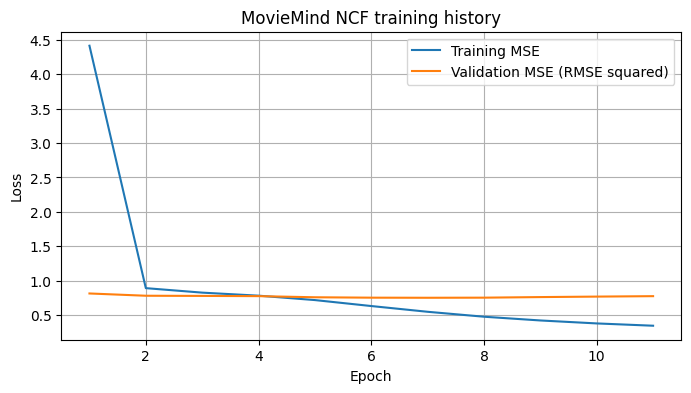

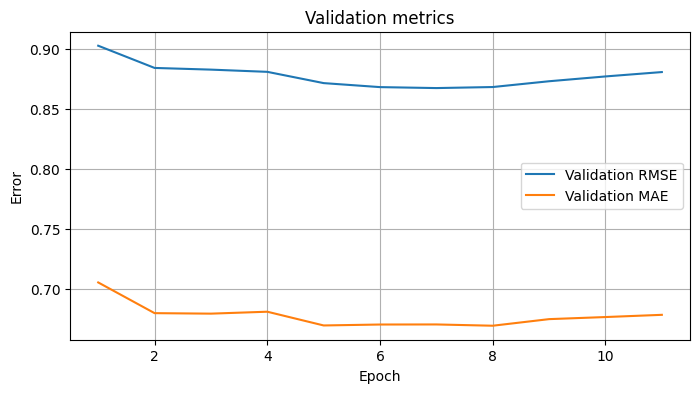

In [13]:
epochs_ran = range(1, len(history['train_loss']) + 1)

plt.figure(figsize=(8, 4))
plt.plot(epochs_ran, history['train_loss'], label='Training MSE')
plt.plot(epochs_ran, np.square(history['validation_rmse']), label='Validation MSE (RMSE squared)')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('MovieMind NCF training history')
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(8, 4))
plt.plot(epochs_ran, history['validation_rmse'], label='Validation RMSE')
plt.plot(epochs_ran, history['validation_mae'], label='Validation MAE')
plt.xlabel('Epoch')
plt.ylabel('Error')
plt.title('Validation metrics')
plt.legend()
plt.grid(True)
plt.show()

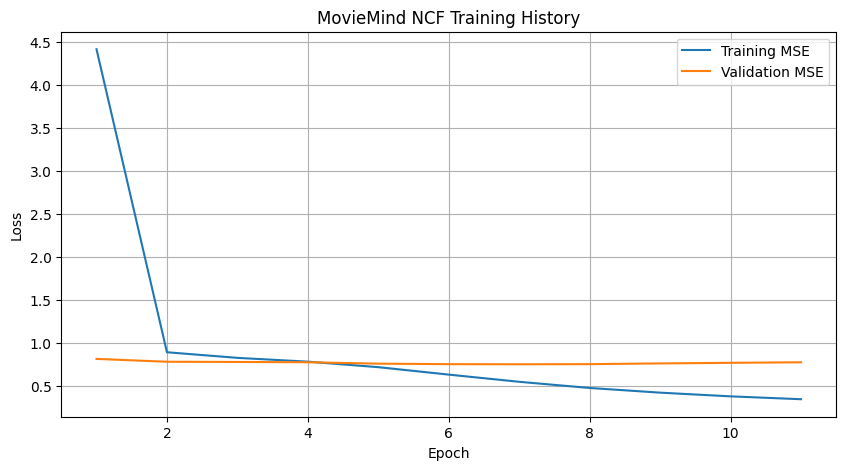

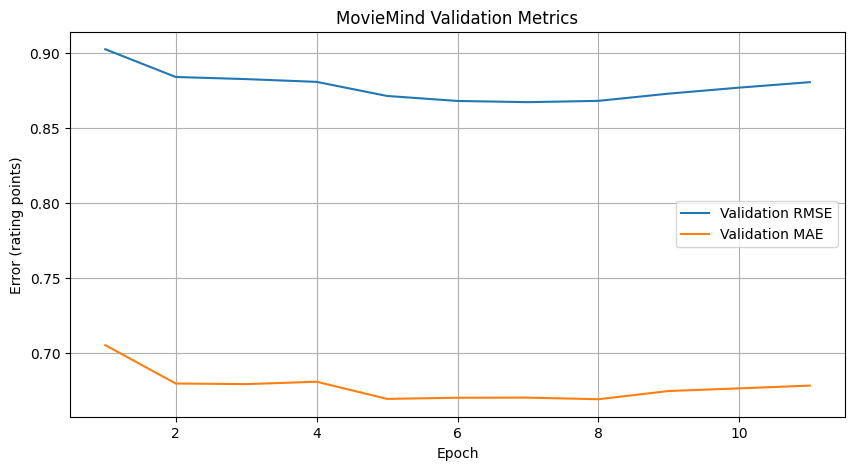

Charts saved successfully!
Location: /content/drive/MyDrive/MovieMind/model_artifacts/charts
Files: ['training_history.png', 'training_history.pdf', 'validation_metrics.png', 'validation_metrics.pdf']


In [22]:

# Save MovieMind training charts to Google Drive

import os
import matplotlib.pyplot as plt
import numpy as np

# Create a dedicated charts folder in Google Drive
CHARTS_DIR = os.path.join(ARTIFACT_DIR, "charts")
os.makedirs(CHARTS_DIR, exist_ok=True)

epochs_ran = range(1, len(history["train_loss"]) + 1)

# Chart 1: Training and validation loss
plt.figure(figsize=(10, 5))
plt.plot(epochs_ran, history["train_loss"], label="Training MSE")
plt.plot(
    epochs_ran,
    np.square(history["validation_rmse"]),
    label="Validation MSE"
)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("MovieMind NCF Training History")
plt.legend()
plt.grid(True)

plt.savefig(
    os.path.join(CHARTS_DIR, "training_history.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.savefig(
    os.path.join(CHARTS_DIR, "training_history.pdf"),
    bbox_inches="tight"
)
plt.show()
plt.close()

# Chart 2: Validation RMSE and MAE
plt.figure(figsize=(10, 5))
plt.plot(epochs_ran, history["validation_rmse"], label="Validation RMSE")
plt.plot(epochs_ran, history["validation_mae"], label="Validation MAE")
plt.xlabel("Epoch")
plt.ylabel("Error (rating points)")
plt.title("MovieMind Validation Metrics")
plt.legend()
plt.grid(True)

plt.savefig(
    os.path.join(CHARTS_DIR, "validation_metrics.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.savefig(
    os.path.join(CHARTS_DIR, "validation_metrics.pdf"),
    bbox_inches="tight"
)
plt.show()
plt.close()

print("Charts saved successfully!")
print("Location:", CHARTS_DIR)
print("Files:", os.listdir(CHARTS_DIR))


In [14]:
test_rmse, test_mae = evaluate(model, test_loader)
print(f'Test RMSE: {test_rmse:.4f}')
print(f'Test MAE:  {test_mae:.4f}')

Test RMSE: 0.8738
Test MAE:  0.6735


In [15]:
# Reverse mapping for displaying the original MovieLens IDs
idx_to_movie = {idx: raw_id for raw_id, idx in movie_to_idx.items()}

rated_movie_ids_by_user = (
    ratings_df.groupby('userId')['movieId'].apply(set).to_dict()
)

def recommend_for_movielens_user(raw_user_id, top_k=10):
    raw_user_id = int(raw_user_id)
    if raw_user_id not in user_to_idx:
        raise ValueError(
            f'Unknown MovieLens user ID {raw_user_id}. '
            f'Choose one of the dataset user IDs.'
        )

    user_idx = user_to_idx[raw_user_id]
    already_rated = rated_movie_ids_by_user.get(raw_user_id, set())

    candidate_movie_ids = [
        raw_id for raw_id in movie_ids if raw_id not in already_rated
    ]
    candidate_indices = [movie_to_idx[mid] for mid in candidate_movie_ids]

    model.eval()
    with torch.no_grad():
        users_tensor = torch.full(
            (len(candidate_indices),), user_idx, dtype=torch.long, device=DEVICE
        )
        movies_tensor = torch.tensor(
            candidate_indices, dtype=torch.long, device=DEVICE
        )
        scores = torch.clamp(model(users_tensor, movies_tensor), 0.5, 5.0)
        scores = scores.cpu().numpy()

    result = pd.DataFrame({
        'movieId': candidate_movie_ids,
        'predicted_rating': scores
    }).merge(movies_df, on='movieId', how='left')

    return result.sort_values('predicted_rating', ascending=False).head(top_k)

example_user_id = int(ratings_df['userId'].value_counts().index[0])
print('Example MovieLens user ID:', example_user_id)
display(recommend_for_movielens_user(example_user_id, top_k=10))

Example MovieLens user ID: 414


,movieId,predicted_rating,title,genres
2315,5746,4.848333,Galaxy of Terror (Quest) (1981),Action|Horror|Mystery|Sci-Fi
2675,6835,4.744872,Alien Contamination (1980),Action|Horror|Sci-Fi
2142,5181,4.719463,Hangar 18 (1980),Action|Sci-Fi|Thriller
2016,4789,4.719269,Phantom of the Paradise (1974),Comedy|Fantasy|Horror|Musical|Thriller
349,905,4.715571,It Happened One Night (1934),Comedy|Romance
2200,5404,4.693585,84 Charing Cross Road (1987),Drama|Romance
1853,4406,4.688117,"Man Who Shot Liberty Valance, The (1962)",Crime|Drama|Western
1882,4454,4.681409,More (1998),Animation|Drama|Sci-Fi|IMAX
1805,4273,4.677526,Under the Sand (2000),Drama
363,930,4.676332,Notorious (1946),Film-Noir|Romance|Thriller


In [17]:
from google.colab import drive
import os

# Mount Google Drive
drive.mount('/content/drive')

# Define MovieMind storage directories
DRIVE_PROJECT_DIR = '/content/drive/MyDrive/MovieMind'

ARTIFACT_DIR = os.path.join(
    DRIVE_PROJECT_DIR,
    'model_artifacts'
)

# Create directories if they don't exist
os.makedirs(ARTIFACT_DIR, exist_ok=True)

print("Google Drive connected!")
print("Model artifacts directory:", ARTIFACT_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Google Drive connected!
Model artifacts directory: /content/drive/MyDrive/MovieMind/model_artifacts


In [18]:
# 11.1 Save model weights
checkpoint_path = os.path.join(ARTIFACT_DIR, 'moviemind_ncf.pt')
torch.save(
    {key: value.detach().cpu() for key, value in model.state_dict().items()},
    checkpoint_path
)

# 11.2 Save model/training configuration
model_config = {
    'model_name': 'MovieMindNCF',
    'model_version': '1.0.0',
    'framework': 'PyTorch',
    'num_users': NUM_USERS,
    'num_movies': NUM_MOVIES,
    'embedding_dim': EMBEDDING_DIM,
    'mlp_hidden_dims': MLP_HIDDEN_DIMS,
    'dropout': DROPOUT,
    'rating_min': 0.5,
    'rating_max': 5.0,
    'dataset': 'MovieLens Latest Small',
    'seed': SEED
}

with open(os.path.join(ARTIFACT_DIR, 'model_config.json'), 'w') as f:
    json.dump(model_config, f, indent=2)

# 11.3 Save original-ID to embedding-index mappings
with open(os.path.join(ARTIFACT_DIR, 'user_mapping.json'), 'w') as f:
    json.dump({str(k): int(v) for k, v in user_to_idx.items()}, f)

with open(os.path.join(ARTIFACT_DIR, 'movie_mapping.json'), 'w') as f:
    json.dump({str(k): int(v) for k, v in movie_to_idx.items()}, f)

# 11.4 Save movie metadata (only fields needed by the app demo)
movies_export = movies_df[['movieId', 'title', 'genres']].copy()
movies_export.to_json(
    os.path.join(ARTIFACT_DIR, 'movies.json'),
    orient='records',
    indent=2
)

# 11.5 Save measured metrics and history
metrics = {
    'test_rmse': test_rmse,
    'test_mae': test_mae,
    'best_validation_rmse': best_val_rmse,
    'epochs_completed': len(history['train_loss']),
    'history': history
}
with open(os.path.join(ARTIFACT_DIR, 'training_metrics.json'), 'w') as f:
    json.dump(metrics, f, indent=2)

print('Saved checkpoint:', checkpoint_path)
print('Checkpoint size (MB):', round(os.path.getsize(checkpoint_path) / (1024**2), 2))

Saved checkpoint: /content/drive/MyDrive/MovieMind/model_artifacts/moviemind_ncf.pt
Checkpoint size (MB): 2.6


In [19]:
model_architecture_source = '''
import torch
import torch.nn as nn

class MovieMindNCF(nn.Module):
    def __init__(
        self,
        num_users: int,
        num_movies: int,
        embedding_dim: int = 32,
        mlp_hidden_dims=(128, 64, 32),
        dropout: float = 0.10
    ):
        super().__init__()
        self.user_gmf = nn.Embedding(num_users, embedding_dim)
        self.movie_gmf = nn.Embedding(num_movies, embedding_dim)
        self.user_mlp = nn.Embedding(num_users, embedding_dim)
        self.movie_mlp = nn.Embedding(num_movies, embedding_dim)

        layers = []
        input_dim = embedding_dim * 2
        for hidden_dim in mlp_hidden_dims:
            layers.extend([
                nn.Linear(input_dim, hidden_dim),
                nn.ReLU(),
                nn.Dropout(dropout)
            ])
            input_dim = hidden_dim
        self.mlp = nn.Sequential(*layers)
        self.output = nn.Linear(embedding_dim + input_dim, 1)

    def forward(self, user_indices, movie_indices):
        gmf = self.user_gmf(user_indices) * self.movie_gmf(movie_indices)
        mlp_input = torch.cat([
            self.user_mlp(user_indices),
            self.movie_mlp(movie_indices)
        ], dim=1)
        mlp_vector = self.mlp(mlp_input)
        return self.output(torch.cat([gmf, mlp_vector], dim=1)).squeeze(1)
'''

architecture_path = os.path.join(ARTIFACT_DIR, 'model_architecture.py')
with open(architecture_path, 'w') as f:
    f.write(model_architecture_source.strip() + '\\n')

inference_example_source = '''
import json
from pathlib import Path

import torch
from model_architecture import MovieMindNCF

ARTIFACT_DIR = Path(__file__).parent

def load_moviemind_model():
    with open(ARTIFACT_DIR / "model_config.json") as f:
        config = json.load(f)

    with open(ARTIFACT_DIR / "user_mapping.json") as f:
        user_mapping = json.load(f)

    with open(ARTIFACT_DIR / "movie_mapping.json") as f:
        movie_mapping = json.load(f)

    model = MovieMindNCF(
        num_users=config["num_users"],
        num_movies=config["num_movies"],
        embedding_dim=config["embedding_dim"],
        mlp_hidden_dims=tuple(config["mlp_hidden_dims"]),
        dropout=config["dropout"]
    )

    state_dict = torch.load(
        ARTIFACT_DIR / "moviemind_ncf.pt",
        map_location="cpu",
        weights_only=True
    )
    model.load_state_dict(state_dict)
    model.eval()
    return model, user_mapping, movie_mapping

# Example for a MovieLens user/movie ID:
# model, users, movies = load_moviemind_model()
# user_idx = users[str(raw_movielens_user_id)]
# movie_idx = movies[str(raw_movielens_movie_id)]
# with torch.no_grad():
#     score = model(
#         torch.tensor([user_idx]),
#         torch.tensor([movie_idx])
#     ).item()
# score = max(0.5, min(5.0, score))
'''

with open(os.path.join(ARTIFACT_DIR, 'inference_example.py'), 'w') as f:
    f.write(inference_example_source.strip() + '\\n')

readme = '''
MovieMind NCF model artifacts
=============================

Files:
- moviemind_ncf.pt: PyTorch state_dict checkpoint
- model_config.json: model architecture/training configuration
- user_mapping.json: raw MovieLens user ID -> embedding index
- movie_mapping.json: raw MovieLens movie ID -> embedding index
- movies.json: MovieLens movie catalog fields (movieId, title, genres)
- training_metrics.json: measured validation/test metrics and training history
- model_architecture.py: matching PyTorch model class
- inference_example.py: example checkpoint loader

All files must remain together. The model was trained on MovieLens Latest Small.
The learned user embeddings correspond only to MovieLens users in user_mapping.json.
A new application user cannot be passed directly as a MovieLens user ID.
Implement a cold-start strategy (e.g. onboarding ratings + user embedding adaptation)
and/or content-based recommendations for new MovieMind users.
'''

with open(os.path.join(ARTIFACT_DIR, 'README.txt'), 'w') as f:
    f.write(readme.strip() + '\\n')

print('Exported architecture, inference example, and README.')

Exported architecture, inference example, and README.


In [20]:
with open(os.path.join(ARTIFACT_DIR, 'model_config.json')) as f:
    saved_config = json.load(f)

reloaded_model = MovieMindNCF(
    num_users=saved_config['num_users'],
    num_movies=saved_config['num_movies'],
    embedding_dim=saved_config['embedding_dim'],
    mlp_hidden_dims=tuple(saved_config['mlp_hidden_dims']),
    dropout=saved_config['dropout']
).to(DEVICE)

reloaded_state = torch.load(
    os.path.join(ARTIFACT_DIR, 'moviemind_ncf.pt'),
    map_location=DEVICE,
    weights_only=True
)
reloaded_model.load_state_dict(reloaded_state)
reloaded_model.eval()

# Compare one prediction from original and reloaded models
sample = test_df.iloc[0]
u = torch.tensor([int(sample['user_idx'])], dtype=torch.long, device=DEVICE)
m = torch.tensor([int(sample['movie_idx'])], dtype=torch.long, device=DEVICE)

with torch.no_grad():
    original_prediction = model(u, m).item()
    reloaded_prediction = reloaded_model(u, m).item()

print('Original prediction:', original_prediction)
print('Reloaded prediction:', reloaded_prediction)
assert abs(original_prediction - reloaded_prediction) < 1e-5
print('Checkpoint reload verification passed.')

Original prediction: 3.818403720855713
Reloaded prediction: 3.818403720855713
Checkpoint reload verification passed.


In [21]:
import shutil

zip_base = os.path.join(DRIVE_PROJECT_DIR, 'moviemind_model_artifacts')
zip_path = shutil.make_archive(zip_base, 'zip', ARTIFACT_DIR)

print('Artifact directory:')
for filename in sorted(os.listdir(ARTIFACT_DIR)):
    full_path = os.path.join(ARTIFACT_DIR, filename)
    print(f'- {filename} ({os.path.getsize(full_path):,} bytes)')

print('ZIP archive:', zip_path)

Artifact directory:
- README.txt (950 bytes)
- inference_example.py (1,278 bytes)
- model_architecture.py (1,314 bytes)
- model_config.json (318 bytes)
- movie_mapping.json (140,158 bytes)
- moviemind_ncf.pt (2,724,971 bytes)
- movies.json (1,008,267 bytes)
- training_metrics.json (1,105 bytes)
- user_mapping.json (7,102 bytes)
ZIP archive: /content/drive/MyDrive/MovieMind/moviemind_model_artifacts.zip
